# 1. Exploration and train/validation/test split

**Problem.** Home Credit lends to people with little or no credit history. Given an application, predict the probability that the borrower will have payment difficulties (`TARGET = 1`). The metric is ROC AUC: the chance that a random defaulter is scored riskier than a random non-defaulter.

This notebook looks at the application table, finds the signals worth modeling, and defines the split used by every later notebook.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import features as F

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

app = F.load_application()
print(app.shape)
print(f"default rate: {app['TARGET'].mean():.2%}")
app.head(3)

(307511, 122)
default rate: 8.07%


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


Only about 8% of borrowers default, so accuracy is a useless metric (always predicting "no default" is 92% accurate). That is why we use AUC.

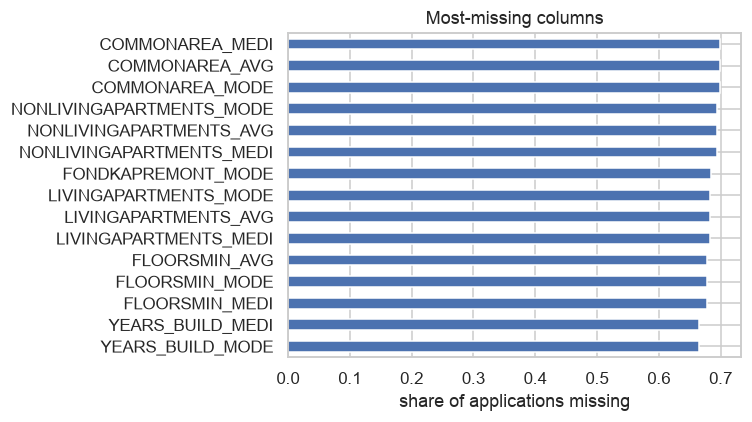

In [2]:
missing = app.isna().mean().sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(7, 4))
missing.iloc[::-1].plot.barh(ax=ax, color="#4c72b0")
ax.set_xlabel("share of applications missing"); ax.set_title("Most-missing columns")
plt.tight_layout(); plt.show()

## Which columns separate defaulters from non-defaulters?

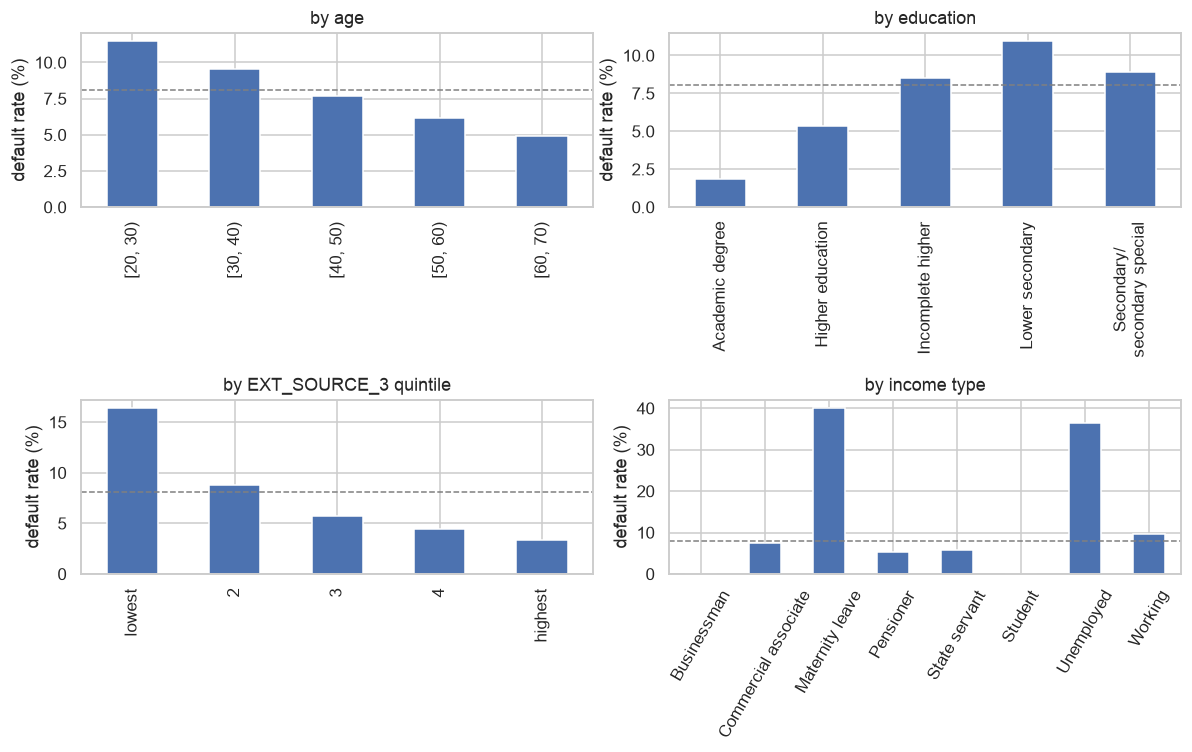

In [3]:
def default_rate_by(series, title, ax):
    rates = app.groupby(series, observed=True)["TARGET"].mean() * 100
    rates.plot.bar(ax=ax, color="#4c72b0"); ax.set_title(title); ax.set_ylabel("default rate (%)"); ax.set_xlabel("")
    ax.axhline(app["TARGET"].mean() * 100, color="gray", ls="--", lw=1)

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
age = pd.cut(-app["DAYS_BIRTH"] / 365, [20, 30, 40, 50, 60, 70], right=False)
default_rate_by(age, "by age", axes[0, 0])
default_rate_by(app["NAME_EDUCATION_TYPE"].str.replace(" / ", "/\n"), "by education", axes[0, 1])
ext3 = pd.qcut(app["EXT_SOURCE_3"], 5, labels=["lowest", "2", "3", "4", "highest"])
default_rate_by(ext3, "by EXT_SOURCE_3 quintile", axes[1, 0])
default_rate_by(app["NAME_INCOME_TYPE"], "by income type", axes[1, 1])
axes[1, 1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig("../reports/default_rate_by_group.png"); plt.show()

The three `EXT_SOURCE_*` columns are scores from external data sources (anonymised). Splitting applicants into five equal groups by `EXT_SOURCE_3`, the default rate runs from about 16% in the lowest group to about 3% in the highest, a far steeper gradient than the hand-picked features used in the first version of this project, which did not use them. Let's check how complete they are and how they relate to the target.

In [4]:
ext = app[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]]
print("share missing:\n", ext.isna().mean().round(3).to_string())
print("\nunivariate AUC (ignoring rows where the score is missing):")
from sklearn.metrics import roc_auc_score
for c in ext:
    ok = ext[c].notna()
    print(f"  {c}: {roc_auc_score(app.loc[ok, 'TARGET'], -ext.loc[ok, c]):.3f}")

share missing:
 EXT_SOURCE_1    0.564
EXT_SOURCE_2    0.002
EXT_SOURCE_3    0.198

univariate AUC (ignoring rows where the score is missing):


  EXT_SOURCE_1: 0.666
  EXT_SOURCE_2: 0.656
  EXT_SOURCE_3: 0.679


## A data quirk: `DAYS_EMPLOYED = 365243`

In [5]:
odd = app["DAYS_EMPLOYED"] == 365243
print(f"{odd.sum():,} applications ({odd.mean():.1%}) have DAYS_EMPLOYED = 365243 (about 1000 years)")
print(app[odd]["NAME_INCOME_TYPE"].value_counts().head(3).to_string())
print(f"default rate: {app[odd]['TARGET'].mean():.2%} vs {app[~odd]['TARGET'].mean():.2%} for everyone else")

55,374 applications (18.0%) have DAYS_EMPLOYED = 365243 (about 1000 years)


NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22


default rate: 5.40% vs 8.66% for everyone else


This is a placeholder for "not employed", almost all pensioners. Treated as a number it would make these people look like the longest-employed in the data, so it is replaced by a missing value plus an indicator flag in the next notebook.

## The split

The original exploration used this split and so does everything after it, so numbers are comparable across notebooks:

- **Test (10%)**: the applications with the highest `SK_ID_CURR`. Held out, scored once per model.
- **Validation (10%)**: random rows from the rest, used for early stopping and for choosing between options.
- **Train (80%)**: everything else.

One honest caveat: the Kaggle IDs are not time-ordered, so "highest IDs" is an arbitrary hold-out rather than a true out-of-time test. In production you would split by application date.

In [6]:
train, valid, test = F.make_splits(app)
pd.DataFrame({"rows": [len(train), len(valid), len(test)],
              "default rate": [train.TARGET.mean(), valid.TARGET.mean(), test.TARGET.mean()]},
             index=["train", "validation", "test"]).round(4)

,rows,default rate
train,246009,0.0808
validation,30751,0.0821
test,30751,0.0791
